In [1]:
# ---------------------------------------------------------------------
# 0. Import Libraries
# ---------------------------------------------------------------------
import sys
import os
import warnings
import numpy as np
import sklearn
import matplotlib
import scipy
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, minimize
from scipy.spatial.distance import pdist
from scipy.stats import rankdata, norm, spearmanr, qmc
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern, ConstantKernel as C

warnings.filterwarnings("ignore")
SEED = 42

print("=" * 100)
print("Software and Libraries used")
print("=" * 100)
print(f"  python      : {sys.version.split()[0]}")
print(f"  numpy       : {np.__version__}")
print(f"  scipy       : {scipy.__version__}")
print(f"  scikit-learn: {sklearn.__version__}")
print(f"  matplotlib  : {matplotlib.__version__}")
print(f"  SEED        : {SEED}")
print()

# Figures Colors and settings
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e6e5e1"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

Software and Libraries used
  python      : 3.13.9
  numpy       : 2.3.5
  scipy       : 1.16.3
  scikit-learn: 1.9.0
  matplotlib  : 3.11.1
  SEED        : 42



In [2]:
# ---------------------------------------------------------------------
# 1. Load the data
# ---------------------------------------------------------------------
X = np.load('..\Function_1_Data\Week_11_Data/F1_Week_11_inputs.npy')
y = np.load('..\Function_1_Data\Week_11_Data/F1_Week_11_outputs.npy')

n = len(y)
N_INITIAL = 10
inc = int(np.argmax(y))
L = np.log10(np.abs(y))

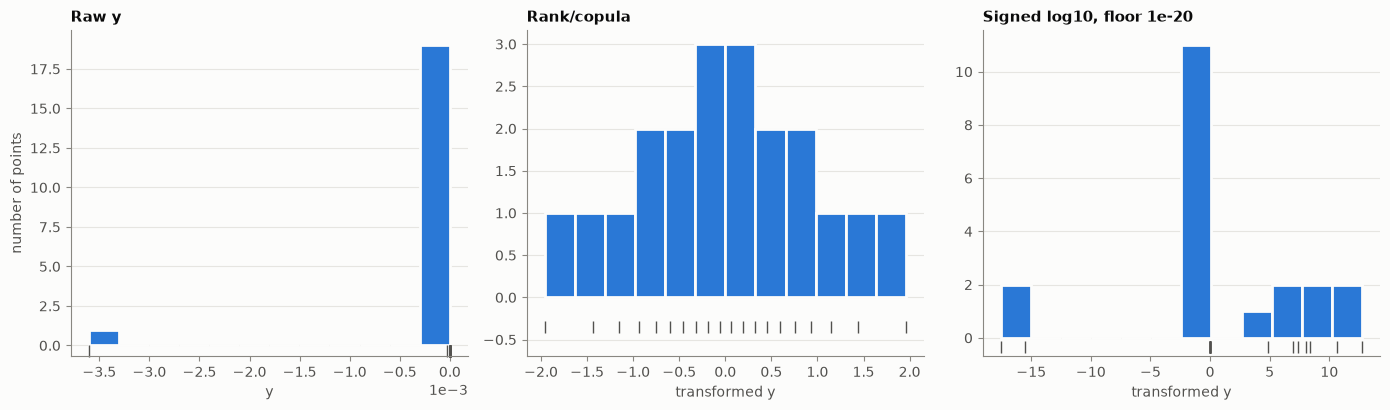

In [3]:
# ---------------------------------------------------------------------
# 2. Re-apply rank-based copula and signed log transforms to all points
# ---------------------------------------------------------------------
def copula(v):
    return norm.ppf((rankdata(v, method="average") - 0.5) / len(v))

FLOOR = -20.0   # |y| below 1e-20 is treated as zero
def signed_log(v):
    return np.sign(v) * np.maximum(np.log10(np.abs(v)) - FLOOR, 0.0)

targets = {"rank/copula": copula(y), "signed log10": signed_log(y)}

# Fig 1: target distributions
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (title, vals, xl) in zip(axes, [("Raw y", y, "y"),
                                        ("Rank/copula", targets["rank/copula"], "transformed y"),
                                        ("Signed log10, floor 1e-20", targets["signed log10"], "transformed y")]):
    ax.hist(vals, bins=12, color=BLUE, edgecolor=SURFACE, linewidth=2)
    ax.plot(vals, np.full(n, -0.35), "|", color=INK2, markersize=9, clip_on=False)
    ax.set_title(title); ax.set_xlabel(xl); ax.set_ylim(bottom=-0.7); ax.grid(axis="x", visible=False)
axes[0].ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
axes[0].set_ylabel("number of points")
fig.tight_layout()

SURROGATES (Matern 5/2, one length-scale per input, bounds 0.02-2.0)
  rank/copula  : length-scales x1=0.0329 x2=0.0438  LOO RMSE/std=0.786  Spearman=0.689  95% coverage=0.95
  signed log10 : length-scales x1=0.0328 x2=0.1065  LOO RMSE/std=0.628  Spearman=0.792  95% coverage=0.95


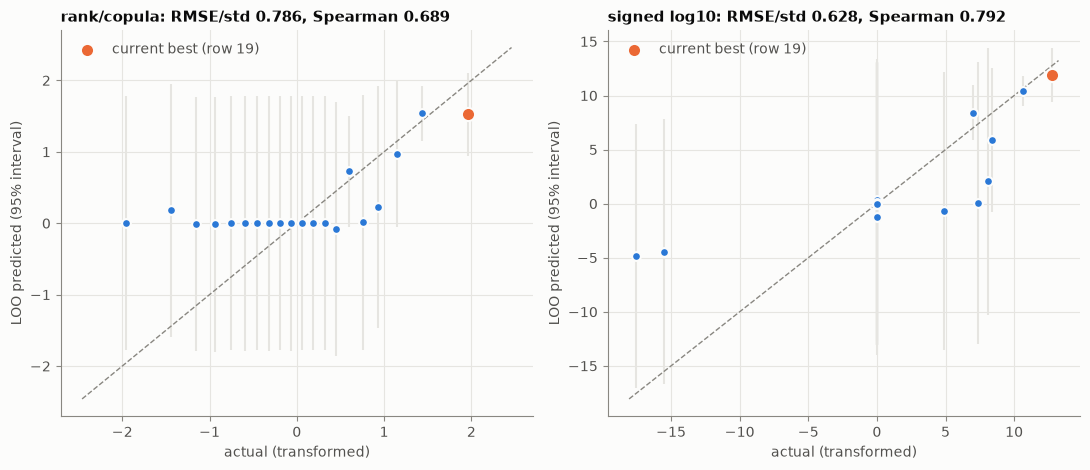

In [4]:
# ---------------------------------------------------------------------
# 3. Refit Matern 5/2 ARD GP on all points and perform LOO-CV
# ---------------------------------------------------------------------
def fit_gp(t):
    init = [np.median(pdist(X[:, [j]])) for j in range(2)]
    k = C(1.0, (1e-2, 1e2)) * Matern(length_scale=init, length_scale_bounds=(0.02, 2.0), nu=2.5)
    return GaussianProcessRegressor(kernel=k, alpha=1e-6, n_restarts_optimizer=15,
                                    random_state=SEED).fit(X, t)

def loo(gp, t):
    mu, sd = np.empty(n), np.empty(n)
    for i in range(n):
        keep = np.arange(n) != i
        g = GaussianProcessRegressor(kernel=gp.kernel_, alpha=1e-6, optimizer=None).fit(X[keep], t[keep])
        a, b = g.predict(X[i:i + 1], return_std=True)
        mu[i], sd[i] = a[0], b[0]
    return mu, sd

gps, loos = {}, {}
print("SURROGATES (Matern 5/2, one length-scale per input, bounds 0.02-2.0)")
for name, t in targets.items():
    gps[name] = fit_gp(t)
    loos[name] = loo(gps[name], t)
    mu, sd = loos[name]
    ls = gps[name].kernel_.k2.length_scale
    print(f"  {name:13s}: length-scales x1={ls[0]:.4f} x2={ls[1]:.4f}  "
          f"LOO RMSE/std={np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}  "
          f"Spearman={spearmanr(t, mu)[0]:.3f}  "
          f"95% coverage={np.mean(np.abs((t - mu) / sd) < 1.96):.2f}")

# Fig 2: LOO predicted vs actual
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, name in zip(axes, targets):
    t = targets[name]; mu, sd = loos[name]
    lim = [min(t.min(), mu.min()) - 0.5, max(t.max(), mu.max()) + 0.5]
    ax.plot(lim, lim, color=MUTED, lw=1, ls="--")
    ax.errorbar(t, mu, yerr=1.96 * sd, fmt="none", ecolor=GRID, elinewidth=1.5, zorder=1)
    ax.scatter(t, mu, s=40, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
    ax.scatter(t[inc], mu[inc], s=90, color=ORANGE, edgecolor=SURFACE, linewidth=1.5, zorder=4,
               label="current best (row 19)")
    ax.set_title(f"{name}: RMSE/std {np.sqrt(np.mean((t - mu) ** 2)) / t.std():.3f}, "
                 f"Spearman {spearmanr(t, mu)[0]:.3f}")
    ax.set_xlabel("actual (transformed)"); ax.set_ylabel("LOO predicted (95% interval)")
    ax.legend(frameon=False, loc="upper left", labelcolor=INK2)
fig.tight_layout()


ENVELOPE MODEL  log10 y = a - k*|x - c|^2  on rows [2, 13, 16, 18, 19]
  a = 0.865  k = 741.6  centre c = (0.623655, 0.632907)
  residuals (decades): [-0.     0.031 -0.097  0.01   0.056]
  leave-one-out centres: x1 0.5865-0.6302, x2 0.5949-0.6638
  width (1 sd of the bump): 0.0171
  sign check, readings within 0.15 of the centre (distance, sign, |y| residual vs envelope):
    row  4  r = 0.0554  -  residual = -1.04 decades
    row 17  r = 0.0876  -  residual = +0.34 decades
    row 19  r = 0.1044  +  residual = -0.06 decades  (in fit)
    row 16  r = 0.1181  +  residual = +0.10 decades  (in fit)
    row 18  r = 0.1297  +  residual = -0.01 decades  (in fit)
    row 13  r = 0.1367  +  residual = -0.03 decades  (in fit)
    row  2  r = 0.1468  +  residual = +0.00 decades  (in fit)


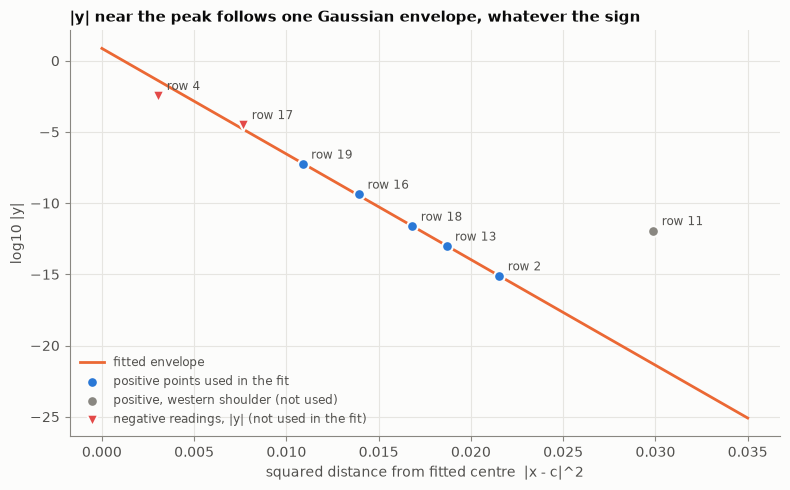

In [ ]:
# ---------------------------------------------------------------------
# 4. Fit a Gaussian bump gives log10|y| = a - k * |x - c|^2 near the isolated peak.
# ---------------------------------------------------------------------

# An envelope is fitted to the positive points on the peak's flanks (rows 2, 13, 16, 18, 19);

ENV = [2, 13, 16, 18, 19]
def env(p, Z):
    a, k, c1, c2 = p
    return a - k * ((Z[:, 0] - c1) ** 2 + (Z[:, 1] - c2) ** 2)

p_env = least_squares(lambda p: env(p, X[ENV]) - L[ENV], [0, 700, 0.6, 0.6]).x
centre = p_env[2:]
jack = np.array([least_squares(lambda p, T=[j for j in ENV if j != i]: env(p, X[T]) - L[T],
                               [0, 700, 0.6, 0.6]).x for i in ENV])
print("\nENVELOPE MODEL  log10 y = a - k*|x - c|^2  on rows", ENV)
print(f"  a = {p_env[0]:.3f}  k = {p_env[1]:.1f}  centre c = ({centre[0]:.6f}, {centre[1]:.6f})")
print(f"  residuals (decades): {np.round(env(p_env, X[ENV]) - L[ENV], 3)}")
print(f"  leave-one-out centres: x1 {jack[:, 2].min():.4f}-{jack[:, 2].max():.4f}, "
      f"x2 {jack[:, 3].min():.4f}-{jack[:, 3].max():.4f}")
print(f"  width (1 sd of the bump): {np.sqrt(np.log10(np.e) / (2 * p_env[1])):.4f}")
r_c = np.linalg.norm(X - centre, axis=1)
print("  sign check, readings within 0.15 of the centre (distance, sign, |y| residual vs envelope):")
for i in np.argsort(r_c):
    if r_c[i] < 0.15:
        print(f"    row {i:2d}  r = {r_c[i]:.4f}  {'+' if y[i] > 0 else '-'}  "
              f"residual = {L[i] - env(p_env, X[i:i+1])[0]:+.2f} decades{'  (in fit)' if i in ENV else ''}")

# ---------------------------------------------------------------------
# Fig 3: envelope fit
# ---------------------------------------------------------------------
d2 = np.sum((X - centre) ** 2, axis=1)
fig, ax = plt.subplots(figsize=(8, 5))
grid = np.linspace(0, 0.035, 50)
ax.plot(grid, p_env[0] - p_env[1] * grid, color=ORANGE, lw=2, label="fitted envelope")
pos_other = [i for i in range(n) if y[i] > 0 and i not in ENV and d2[i] < 0.035]
neg_near = [i for i in range(n) if y[i] < 0 and d2[i] < 0.035]
ax.scatter(d2[ENV], L[ENV], s=60, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3,
           label="positive points used in the fit")
ax.scatter(d2[pos_other], L[pos_other], s=60, color=MUTED, edgecolor=SURFACE, linewidth=1.5, zorder=3,
           label="positive, western shoulder (not used)")
ax.scatter(d2[neg_near], L[neg_near], s=70, marker="v", color=RED, edgecolor=SURFACE, linewidth=1.5, zorder=3,
           label="negative readings, |y| (not used in the fit)")
for i in ENV + pos_other + neg_near:
    ax.annotate(f"row {i}", (d2[i], L[i]), xytext=(6, 4), textcoords="offset points", fontsize=8.5, color=INK2)
ax.set_xlabel("squared distance from fitted centre  |x - c|^2")
ax.set_ylabel("log10 |y|")
ax.set_title("|y| near the peak follows one Gaussian envelope, whatever the sign")
ax.legend(frameon=False, loc="lower left", labelcolor=INK2, fontsize=8.5)
fig.tight_layout()

In [6]:
# ---------------------------------------------------------------------
# 5. Candidate Models
# ---------------------------------------------------------------------

gp_c = gps["rank/copula"]
f_best = targets["rank/copula"].max()

def ei(Z, xi=0.0):
    mu, s = gp_c.predict(Z, return_std=True)
    s = np.maximum(s, 1e-12)
    z = (mu - f_best - xi) / s
    return (mu - f_best - xi) * norm.cdf(z) + s * norm.pdf(z)

S = np.vstack([qmc.Sobol(2, seed=1).random(2 ** 14), X])
v = ei(S)
x_ei, best = S[v.argmax()], v.max()
for x0 in S[np.argsort(-v)[:15]]:
    r = minimize(lambda x: -ei(x[None])[0], x0, bounds=[(0, 1)] * 2, method="L-BFGS-B")
    if -r.fun > best:
        x_ei, best = r.x, -r.fun

midpoint = X[inc] + 0.5 * (centre - X[inc])
cands = {
    "A: GP-EI (copula, xi=0)": x_ei,
    "B: half-way step to envelope centre": midpoint,
    "C: envelope centre": centre,
}
print("\nCANDIDATES")
for name, xc in cands.items():
    pc = env(p_env, xc[None])[0]
    mu_c, sd_c = gp_c.predict(xc[None], return_std=True)
    print(f"  {name:38s} x = ({xc[0]:.6f}, {xc[1]:.6f})  dist to incumbent = "
          f"{np.linalg.norm(xc - X[inc]):.4f}  envelope log10 y = {pc:+.2f}  "
          f"GP copula mean = {mu_c[0]:+.2f} +/- {sd_c[0]:.2f}")


CANDIDATES
  A: GP-EI (copula, xi=0)                x = (0.556050, 0.566943)  dist to incumbent = 0.0162  envelope log10 y = -5.75  GP copula mean = +2.02 +/- 0.33
  B: half-way step to envelope centre    x = (0.591327, 0.591954)  dist to incumbent = 0.0522  envelope log10 y = -1.15  GP copula mean = +0.44 +/- 0.80
  C: envelope centre                     x = (0.623655, 0.632907)  dist to incumbent = 0.1044  envelope log10 y = +0.86  GP copula mean = -0.75 +/- 0.85


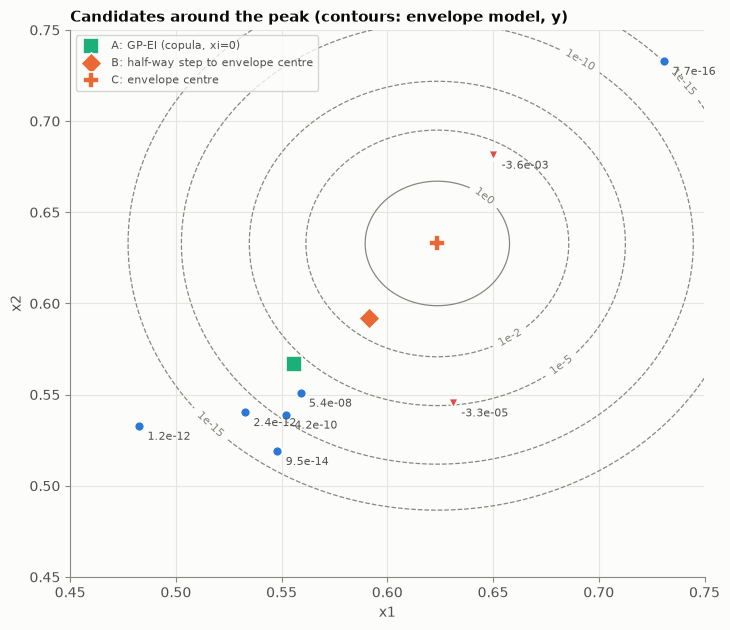

In [7]:
# Fig 4: zoomed map with candidates
lo, hi = 0.45, 0.75
fig, ax = plt.subplots(figsize=(7.4, 6.4))
g1 = np.linspace(lo, hi, 200)
G1, G2 = np.meshgrid(g1, g1)
E = env(p_env, np.column_stack([G1.ravel(), G2.ravel()])).reshape(G1.shape)
cs = ax.contour(G1, G2, E, levels=[-15, -10, -5, -2, 0], colors=MUTED, linewidths=0.9)
ax.clabel(cs, fmt=lambda v: f"1e{int(v)}", fontsize=8)
inside = np.all((X >= lo) & (X <= hi), axis=1)
for i in np.where(inside)[0]:
    col = RED if y[i] < 0 else BLUE
    ax.scatter(*X[i], s=55, color=col, edgecolor=SURFACE, linewidth=1.5, zorder=3,
               marker="v" if y[i] < 0 else "o")
    ax.annotate(f"{y[i]:.1e}", X[i], xytext=(6, -10), textcoords="offset points", fontsize=8, color=INK2)
marks = {"A: GP-EI (copula, xi=0)": ("s", AQUA), "B: half-way step to envelope centre": ("D", ORANGE),
         "C: envelope centre": ("P", ORANGE)}
for name, xc in cands.items():
    m, c = marks[name]
    ax.scatter(*xc, s=120, marker=m, color=c, edgecolor=SURFACE, linewidth=1.2, zorder=5, label=name)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_xlabel("x1"); ax.set_ylabel("x2")
ax.set_title("Candidates around the peak (contours: envelope model, y)")
ax.legend(frameon=True, loc="upper left", fontsize=8, labelcolor=INK2)
fig.tight_layout()
plt.show()

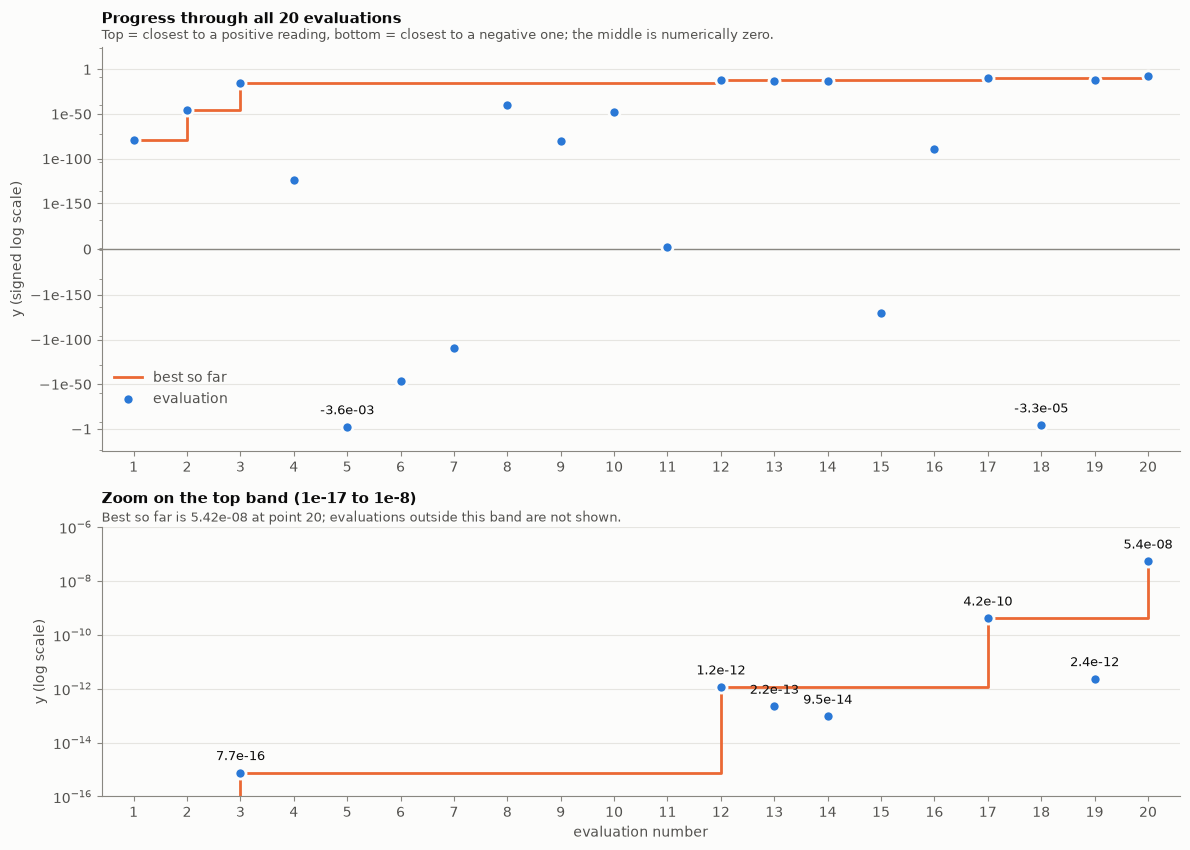

In [ ]:
# Progress through all points
idx = np.arange(1, n + 1)

best = np.maximum.accumulate(y)
inc = int(np.argmax(y))
fig, (ax, az) = plt.subplots(2, 1, figsize=(12, 8.6), height_ratios=[3, 2])
ax.axhline(0, color=MUTED, linewidth=1)
ax.step(idx, best, where="post", color=ORANGE, linewidth=2, label="best so far", zorder=2)
ax.scatter(idx, y, s=64, color=BLUE, edgecolor=SURFACE, linewidth=2, label="evaluation", zorder=3)
ax.set_yscale("symlog", linthresh=1e-200)
ticks = [-1e0, -1e-50, -1e-100, -1e-150, 0, 1e-150, 1e-100, 1e-50, 1e0]
ax.set_yticks(ticks)
ax.set_yticklabels(["−1", "−1e-50", "−1e-100", "−1e-150", "0", "1e-150", "1e-100", "1e-50", "1"])
ax.set_ylim(-1e25, 1e25)
ax.set_ylabel("y (signed log scale)")
for i in (4, 17):
    ax.annotate(f"{y[i]:.1e}", (idx[i], y[i]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0.0, 0.08), labelcolor=INK2)
ax.set_title("Progress through all 20 evaluations\n", pad=4)
ax.text(0, 1.02, "Top = closest to a positive reading, bottom = closest to a negative one; "
        "the middle is numerically zero.", transform=ax.transAxes, color=INK2, fontsize=9)

lo, hi = 1e-16, 1e-6
m = (y > lo) & (y < hi)
az.step(idx, best, where="post", color=ORANGE, linewidth=2, zorder=2)
az.scatter(idx[m], y[m], s=64, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
az.set_yscale("log")
az.set_ylim(lo, hi)
for i in np.where(m)[0]:
    az.annotate(f"{y[i]:.1e}", (idx[i], y[i]), xytext=(0, 9), textcoords="offset points",
                ha="center", fontsize=9, color=INK)
az.set_ylabel("y (log scale)")
az.set_xlabel("evaluation number")
az.set_title("Zoom on the top band (1e-17 to 1e-8)\n", pad=4)
az.text(0, 1.02, f"Best so far is {y[inc]:.2e} at point {inc + 1}; evaluations outside this band are not shown.",
        transform=az.transAxes, color=INK2, fontsize=9)
for a_ in (ax, az):
    a_.set_xticks(idx)
    a_.set_xlim(0.4, n + 0.6)
    a_.grid(axis="x", visible=False)
fig.tight_layout()
